# 02 — Exploratory data analysis

Scaffold. Begin with the reviewed QC series and workbook hash from
[01 — Standardization](01_standardization.ipynb).

## Planned analysis

- Inspect case trends, year-to-year coverage, and seasonality by source block.
- Show the COVID flag and weather coverage alongside the observed counts.
- Explore lagged weather associations with explicit overlap and sample sizes.
  Define the direction of each lag and consider shared seasonality and autocorrelation.

## Handoff

Record the observed patterns, coverage limitations, and candidate questions for
[03 — Feature engineering](03_feature_engineering.ipynb). Keep selection informed
by modeling work inside the training periods and reserve evaluation periods.

In [2]:
import sys
from pathlib import Path

root = Path.cwd()
if root.name == "notebooks":
    root = root.parent
sys.path.insert(0, str(root))

from services.engine.upri_data import load_weekly

qc, case_column, _ = load_weekly("QUEZON_CITY")
observed = qc.dropna(subset=[case_column])

In [3]:
import pandas as pd

weather_fields = [
    field for field in observed.columns
    if field not in {"YR", "WN", case_column}
    and not field.startswith("FLAG_")
]

def source_week(row):
    return f"{int(row['YR'])}-{int(row['WN']):02d}"

coverage_rows = []
for field in weather_fields:
    available = observed.loc[observed[field].notna(), ["YR", "WN"]]
    coverage_rows.append({
        "Weather field": field,
        "Weeks available": len(available),
        "Weeks missing": len(observed) - len(available),
        "Coverage (%)": 100 * len(available) / len(observed),
        "First source week": source_week(available.iloc[0]) if len(available) else None,
        "Last source week": source_week(available.iloc[-1]) if len(available) else None,
    })

weather_coverage = pd.DataFrame(coverage_rows).set_index("Weather field")
display(weather_coverage.round(1))

,Weeks available,Weeks missing,Coverage (%),First source week,Last source week
Weather field,,,,,
RF_NASA,832,0,100.0,2010-01,2025-52
RF_PAGASA,260,572,31.2,2019-01,2025-52
Temp_ERA5-Land,832,0,100.0,2010-01,2025-52
TempMax_ERA5-Land,832,0,100.0,2010-01,2025-52
TempMin_ERA5-Land,832,0,100.0,2010-01,2025-52
RH_ERA5-Land,832,0,100.0,2010-01,2025-52
RHMax_ERA5-Land,832,0,100.0,2010-01,2025-52
RHMin_ERA5-Land,832,0,100.0,2010-01,2025-52
Pressure_ERA5-Land,819,13,98.4,2010-01,2025-39


In [4]:
import pandas as pd

weather_to_explore = ["RF_NASA", "Temp_ERA5-Land", "RH_ERA5-Land"]
series = qc[[case_column, *weather_to_explore]]

# Compare each observation with the median for its own source week.
usual = series.groupby(qc["WN"]).transform("median")
departures = series - usual

lag_rows = []
for weather in weather_to_explore:
    for lag in range(13):
        pairs = pd.DataFrame({
            "weather": series[weather].shift(lag),
            "cases": series[case_column],
            "weather_departure": departures[weather].shift(lag),
            "case_departure": departures[case_column],
        }).dropna()

        lag_rows.append({
            "Weather": weather,
            "Lag (source weeks)": lag,
            "Paired weeks": len(pairs),
            "Raw Spearman": pairs["weather"].corr(
                pairs["cases"], method="spearman"
            ),
            "Seasonal departures Spearman": pairs["weather_departure"].corr(
                pairs["case_departure"], method="spearman"
            ),
        })

weather_lags = pd.DataFrame(lag_rows)
display(weather_lags.round(3))

,Weather,Lag (source weeks),Paired weeks,Raw Spearman,Seasonal departures Spearman
0,RF_NASA,0,832,0.324,0.078
1,RF_NASA,1,831,0.354,0.061
2,RF_NASA,2,830,0.380,0.067
3,RF_NASA,3,829,0.419,0.107
4,RF_NASA,4,828,0.435,0.097
5,RF_NASA,5,827,0.446,0.078
6,RF_NASA,6,826,0.454,0.084
7,RF_NASA,7,825,0.434,0.075
8,RF_NASA,8,824,0.410,0.082
9,RF_NASA,9,823,0.394,0.083


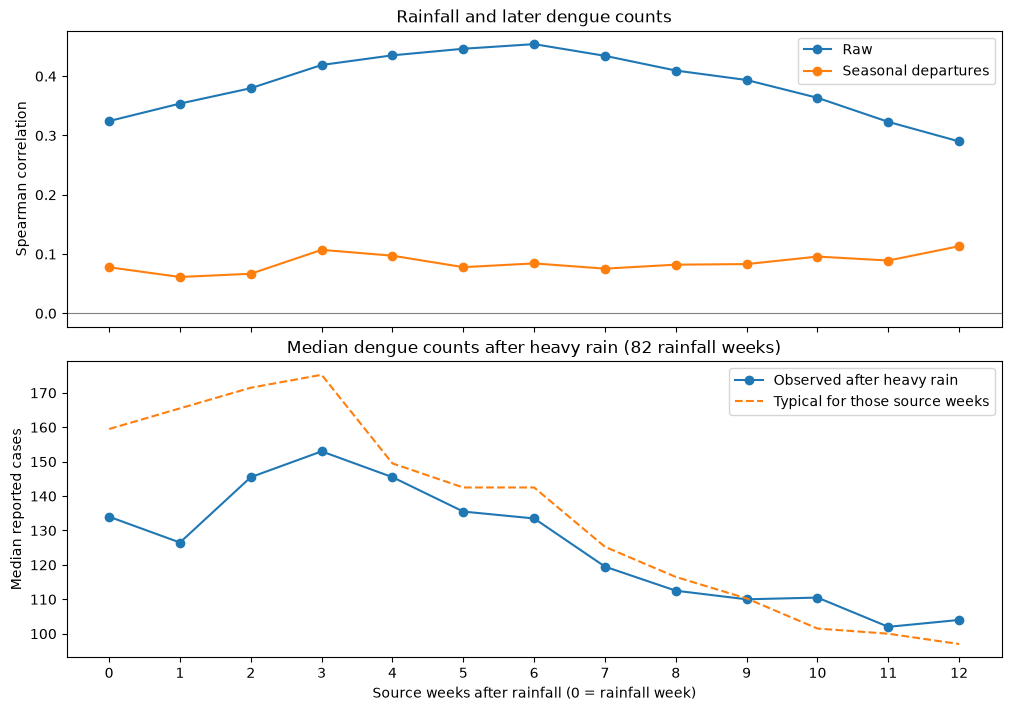

Peak raw correlation: +6 weeks (0.454)
Heavy-rain threshold: 128.9 mm per source week
Peak observed median: +3 weeks (153 cases)


In [5]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

root = Path.cwd()
if root.name == "notebooks":
    root = root.parent
sys.path.insert(0, str(root))

from services.engine.upri_data import load_weekly

qc, case_column, _ = load_weekly("QUEZON_CITY")
rain = qc["RF_NASA"]
cases = qc[case_column]
usual_rain = rain.groupby(qc["WN"]).transform("median")
usual_cases = cases.groupby(qc["WN"]).transform("median")
lags = range(13)

# Plot 1: Pair rainfall with cases 0–12 source weeks later.
correlations = pd.DataFrame({
    "Raw": [
        rain.shift(lag).corr(cases, method="spearman") for lag in lags
    ],
    "Seasonal departures": [
        (rain - usual_rain).shift(lag).corr(
            cases - usual_cases, method="spearman"
        )
        for lag in lags
    ],
}, index=lags)

# Plot 2: Align heavy-rain weeks at 0 and keep complete follow-up windows.
threshold = rain.quantile(0.90)
rain_weeks = rain.index[rain.ge(threshold)]
followup = pd.DataFrame({
    lag: cases.reindex(rain_weeks + lag).to_numpy() for lag in lags
}, index=rain_weeks).dropna()
typical = pd.DataFrame({
    lag: usual_cases.reindex(followup.index + lag).to_numpy() for lag in lags
}, index=followup.index)

median_cases = followup.median()
median_typical = typical.median()

fig, (ax1, ax2) = plt.subplots(
    2, 1, figsize=(10, 7), sharex=True, layout="constrained"
)

correlations.plot(ax=ax1, marker="o")
ax1.axhline(0, color="gray", linewidth=0.8)
ax1.set(
    title="Rainfall and later dengue counts",
    ylabel="Spearman correlation",
)

ax2.plot(lags, median_cases, marker="o", label="Observed after heavy rain")
ax2.plot(lags, median_typical, linestyle="--", label="Typical for those source weeks")
ax2.set(
    title=f"Median dengue counts after heavy rain ({len(followup)} rainfall weeks)",
    xlabel="Source weeks after rainfall (0 = rainfall week)",
    ylabel="Median reported cases",
    xticks=list(lags),
)
ax2.legend()
plt.show()

raw_peak = correlations["Raw"].idxmax()
case_peak = median_cases.idxmax()
print(f"Peak raw correlation: +{raw_peak} weeks ({correlations.loc[raw_peak, 'Raw']:.3f})")
print(f"Heavy-rain threshold: {threshold:.1f} mm per source week")
print(f"Peak observed median: +{case_peak} weeks ({median_cases.loc[case_peak]:.0f} cases)")